# Module 9 (bonus) — Les modèles de langage de protéines

> **Objectif** : transposer tout le cours à un « langage » particulier : les **séquences protéiques**. On voit ce qui se transfère tel quel (Transformers, MLM, affinage, étiquetage de tokens, LoRA, multi-tâche) et ce qui change (tokenisation par résidu, co-évolution, homologie et fuite, absence de « mots »). On construit, en NumPy, deux démonstrations clés : **la co-évolution comme signal de contact** (ce qu'un PLM apprend sans supervision) et **l'étiquetage de régions** d'un domaine de type immunoglobuline avec un **décodage structuré** (Viterbi). Puis on écrit le code pour **ESM-2** : embeddings, étiquetage de régions par token, LoRA, et prédiction zéro-shot de l'effet des mutations.

| | |
|---|---|
| **Durée estimée** | 3 h |
| **Prérequis** | Modules 0 à 8 |
| **Librairies** | `numpy`, `matplotlib`, `scikit-learn` ; `torch`, `transformers`, `peft` (sections 6 à 8) |

**Plan**

1. Les protéines comme langage : ce qui se transfère, ce qui change
2. Tokenisation et vocabulaire
3. Ce que le MLM apprend : la co-évolution (démonstration NumPy)
4. Une tâche d'étiquetage de régions : un simulateur de domaines V
5. Baseline par fenêtre glissante et décodage structuré (Viterbi)
6. ESM-2 avec Hugging Face : embeddings et pseudo-perplexité
7. Affiner ESM-2 pour l'étiquetage de régions (complet ou LoRA)
8. Prédiction zéro-shot de l'effet des mutations
9. Modèles spécialisés, DAPT et pièges propres au domaine
10. Récapitulatif et exercices

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({
    "figure.figsize": (7, 4), "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": "#e6e5e0", "lines.linewidth": 2, "axes.titleweight": "bold",
    "legend.frameon": False, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
})
rng = np.random.default_rng(0)
AA = "ACDEFGHIKLMNPQRSTVWY"
aidx = {a: i for i, a in enumerate(AA)}

## 1. Les protéines comme langage

### 💡 L'analogie

| NLP | Protéines |
|---|---|
| alphabet / tokens | 20 acides aminés (+ quelques symboles rares) |
| phrases | séquences de 50 à 2 000+ résidus |
| grammaire, sens | contraintes physico-chimiques, repliement, fonction |
| hypothèse distributionnelle | un résidu se comprend par son **contexte** : conservation, co-variation |
| corpus massif non annoté | UniProt / UniRef (des centaines de millions de séquences) ; OAS pour les anticorps |
| données annotées rares | structures, fonctions, annotations expertes (par exemple IMGT) |

L'évolution a joué le rôle du « locuteur » : les séquences observées aujourd'hui sont celles qui se replient et fonctionnent. Un modèle qui apprend à **prédire un résidu masqué** à partir du reste doit donc capturer implicitement ces contraintes : quels résidus sont tolérés à chaque position, lesquels co-varient parce qu'ils sont en contact dans la structure 3D. C'est exactement l'objectif MLM du module 7, appliqué à un autre langage.

### Ce qui change vraiment

1. **Pas de mots** : pas d'espaces, pas de morphologie évidente → tokenisation par résidu (section 2).
2. **Dépendances à longue distance** : deux résidus éloignés de 80 positions peuvent être en contact. L'attention (module 6) y est naturellement adaptée ; un RNN beaucoup moins.
3. **Homologie** : les séquences sont apparentées par descendance. Un split aléatoire mélange des homologues entre entraînement et test, et gonfle les scores (module 8, section 5). Le split par **cluster d'identité** est indispensable.
4. **Redondance du corpus** : certaines familles comptent des milliers de quasi-copies. ESM échantillonne l'entraînement par **clusters** (UniRef50 / UniRef90) pour ne pas sur-représenter les familles très séquencées.
5. **Évaluation par la biologie** : contacts, stabilité, effets de mutations mesurés expérimentalement (*deep mutational scanning*), annotations expertes.

## 2. Tokenisation et vocabulaire

La grande majorité des modèles de protéines (ESM, ProtBERT, AbLang…) utilisent **un token par résidu**. Le vocabulaire d'ESM-2 compte 33 tokens : 20 acides aminés standards, des codes rares ou ambigus (X, B, U, Z, O), et des tokens spéciaux (`<cls>`, `<pad>`, `<eos>`, `<unk>`, `<mask>`…). Quelques modèles génératifs (ProtGPT2) utilisent un BPE, qui fusionne des motifs fréquents.

**Conséquences pratiques** :
- l'alignement étiquettes / tokens est **trivial** (un résidu = un token), contrairement aux sous-mots du module 7 : seuls les tokens spéciaux `<cls>` (début) et `<eos>` (fin) reçoivent `-100` ;
- la longueur en tokens = la longueur de la séquence (+2). Avec une attention en $O(T^2)$ (module 6), les longues protéines coûtent cher ; les modèles ont une longueur maximale (1 024 pour ESM-2) au-delà de laquelle il faut découper ;
- la **perplexité** est par résidu, comparable entre modèles qui partagent cette tokenisation. Un modèle uniforme a une perplexité de 20.

uniform perplexity = 20.00 | unigram (composition) perplexity = 17.97
a protein language model must go well below this (the largest ESM-2 models reach a perplexity of roughly 6-7 on held-out UniRef50 clusters)


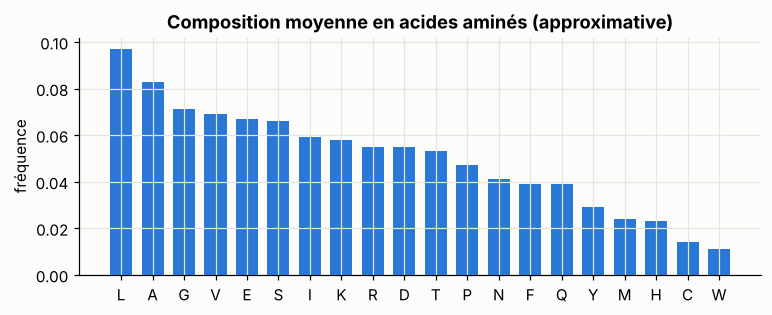

In [2]:
# Per-residue "language model" baselines: uniform vs composition (unigram)
# Approximate amino-acid background frequencies in natural proteins (UniProt-like composition, in %):
bg = {"A": 8.3, "R": 5.5, "N": 4.1, "D": 5.5, "C": 1.4, "Q": 3.9, "E": 6.7, "G": 7.1, "H": 2.3, "I": 5.9,
      "L": 9.7, "K": 5.8, "M": 2.4, "F": 3.9, "P": 4.7, "S": 6.6, "T": 5.3, "W": 1.1, "Y": 2.9, "V": 6.9}
p_bg = np.array([bg[a] for a in AA]); p_bg /= p_bg.sum()
entropy = -(p_bg * np.log(p_bg)).sum()
print(f"uniform perplexity = 20.00 | unigram (composition) perplexity = {np.exp(entropy):.2f}")
print("a protein language model must go well below this (the largest ESM-2 models reach a perplexity of roughly 6-7 on held-out UniRef50 clusters)")
plt.figure(figsize=(8, 2.8))
order = np.argsort(-p_bg)
plt.bar([AA[i] for i in order], p_bg[order], color=PALETTE[0], width=0.7)
plt.title("Composition moyenne en acides aminés (approximative)"); plt.ylabel("fréquence")
plt.show()

## 3. Ce que le MLM apprend : la co-évolution

### 💡 Intuition

Si deux résidus $i$ et $j$ sont en **contact** dans la structure, une mutation en $i$ qui déstabilise l'interaction est souvent compensée par une mutation en $j$. Sur un alignement de séquences homologues, les colonnes $i$ et $j$ **co-varient**. Un modèle MLM qui doit prédire le résidu masqué en $j$ a tout intérêt à regarder la position $i$ : la co-évolution est un signal de prédiction. On a montré que les cartes d'attention d'ESM capturent ainsi les contacts de la structure 3D, sans jamais avoir vu de structure (Rao et al., 2021).

### 📐 La mesure classique : l'information mutuelle corrigée

Sur un alignement multiple (MSA), pour deux colonnes $i, j$ :
$$
\mathrm{MI}(i,j) = \sum_{a,b} f_{ij}(a,b)\log\frac{f_{ij}(a,b)}{f_i(a)\,f_j(b)}
$$
(même forme que la PMI du module 3, mais moyennée). Le signal brut est pollué par la **phylogénie** et l'entropie propre des colonnes ; la **correction du produit moyen** (APC, Dunn et al., 2008) retire ce bruit de fond :
$$
\mathrm{MI}^{\text{APC}}(i,j) = \mathrm{MI}(i,j) - \frac{\overline{\mathrm{MI}}(i,\cdot)\;\overline{\mathrm{MI}}(\cdot,j)}{\overline{\mathrm{MI}}}
$$

### 📊 Démonstration

On simule un MSA de 3 000 séquences de longueur 50 : chaque position a sa propre distribution (conservation variable), et 10 paires de positions « en contact » sont **couplées** (le résidu en $j$ dépend de celui en $i$ dans 80 % des cas).

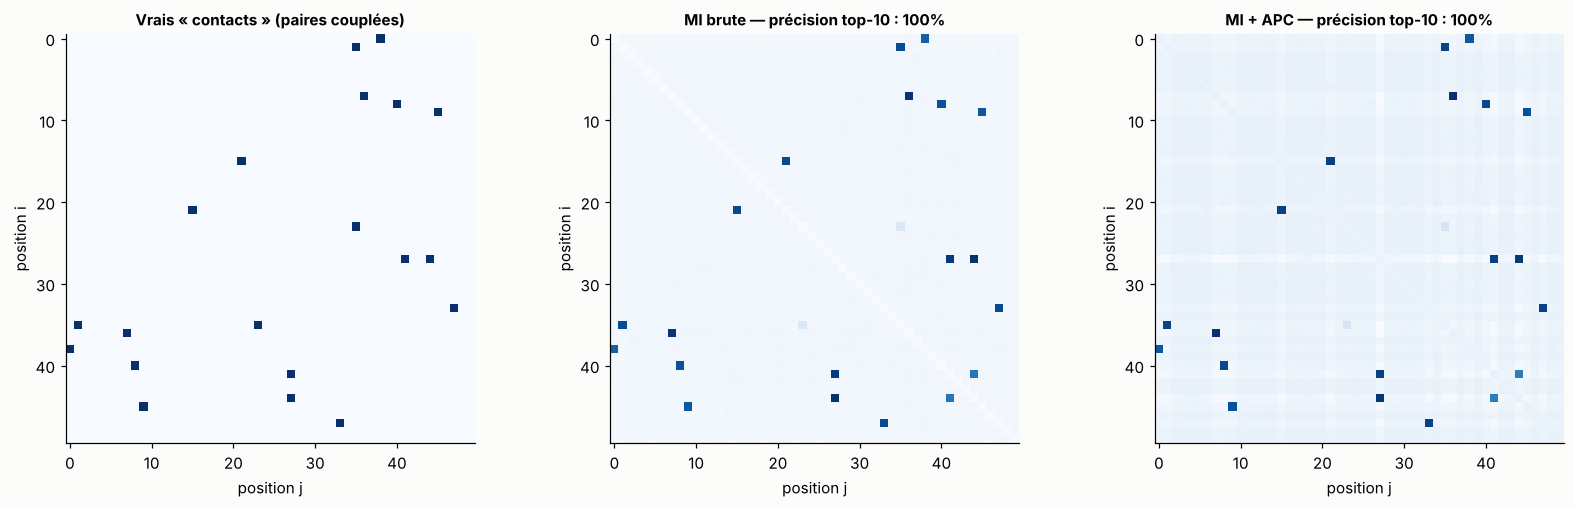

In [3]:
L_msa, N_msa = 50, 3000
r = np.random.default_rng(1)
site_probs = r.dirichlet(np.full(20, 0.5), size=L_msa)                     # per-position residue preferences
msa = np.stack([r.choice(20, N_msa, p=site_probs[i]) for i in range(L_msa)], axis=1)
contacts = set()
while len(contacts) < 10:
    i, j = sorted(r.choice(L_msa, 2, replace=False))
    if j - i >= 6:
        contacts.add((i, j))
for i, j in contacts:
    mapping = r.permutation(20)                                             # "compensatory" substitution rule
    coupled = r.random(N_msa) < 0.8
    msa[coupled, j] = mapping[msa[coupled, i]]

def mutual_information(msa, pseudo=0.5):
    L = msa.shape[1]
    oh = np.eye(20)[msa]                                                    # (N, L, 20)
    f1 = (oh.sum(0) + pseudo / 20) / (len(msa) + pseudo)                   # (L, 20)
    MI = np.zeros((L, L))
    for i in range(L):
        fij = (np.einsum("na,nlb->lab", oh[:, i], oh) + pseudo / 400) / (len(msa) + pseudo)   # (L, 20, 20)
        MI[i] = (fij * np.log(fij / (f1[i][None, :, None] * f1[:, None, :]))).sum((1, 2))
    np.fill_diagonal(MI, 0)
    return MI

MI = mutual_information(msa)
mean_row = MI.sum(1) / (L_msa - 1)
MI_apc = MI - np.outer(mean_row, mean_row) / (MI.sum() / (L_msa * (L_msa - 1)))
np.fill_diagonal(MI_apc, 0)

true_map = np.zeros((L_msa, L_msa))
for i, j in contacts:
    true_map[i, j] = true_map[j, i] = 1

def top_pairs_precision(M, k=10, min_sep=6):
    iu = [(i, j) for i in range(L_msa) for j in range(i + min_sep, L_msa)]
    best = sorted(iu, key=lambda p: -M[p])[:k]
    return np.mean([p in contacts for p in best])

fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
for ax, (M, title) in zip(axes, [(true_map, "Vrais « contacts » (paires couplées)"),
                                 (MI, f"MI brute — précision top-10 : {top_pairs_precision(MI):.0%}"),
                                 (MI_apc, f"MI + APC — précision top-10 : {top_pairs_precision(MI_apc):.0%}")]):
    ax.imshow(M, cmap="Blues"); ax.set_title(title, fontsize=10); ax.grid(False)
    ax.set_xlabel("position j"); ax.set_ylabel("position i")
plt.tight_layout(); plt.show()

Ici, les séquences sont générées **indépendamment** (pas de phylogénie) : MI brute et corrigée retrouvent toutes deux les couplages. Sur de vrais MSA, la phylogénie crée de nombreuses fausses corrélations et la correction APC (ou des modèles globaux comme la DCA) devient indispensable : c'est l'objet de l'exercice 3.

Un MLM n'a pas besoin de MSA : en apprenant à prédire des résidus masqués sur des millions de familles, il internalise ce type de dépendance **dans ses poids**. C'est pourquoi un PLM est utile même pour une séquence isolée, sans homologue connu.

## 4. Une tâche d'étiquetage de régions : un simulateur de domaines V

### Le contexte biologique

Les domaines variables (V) des immunoglobulines et des récepteurs T alternent des régions **charpente** (*framework*, FR1 à FR4), relativement conservées, et des régions **déterminant la complémentarité** (CDR1 à CDR3), hypervariables, qui forment le site de liaison à l'antigène. La numérotation unique IMGT (Lefranc et al.) définit des positions standardisées : FR1 1–26, CDR1 27–38, FR2 39–55, CDR2 56–65, FR3 66–104, CDR3 105–117, FR4 118–128, avec des ancres conservées (1er Cys en 23, Trp conservé en 41, 2e Cys en 104, motif J-Trp/Phe-Gly-X-Gly en 118–121).

**Délimiter ces régions est une tâche d'étiquetage de tokens** (module 7) : une étiquette par résidu, et des **segments contigus dans un ordre imposé** FR1 → CDR1 → FR2 → CDR2 → FR3 → CDR3 → FR4.

### Le simulateur

Pour que ce notebook soit autonome, on génère des séquences **synthétiques** inspirées de cette organisation (ce ne sont **pas** de vraies séquences, et les longueurs sont simplifiées) :
- 8 « gènes germinaux » **apparentés** : un jeu de charpentes ancestral (aléatoire, avec les ancres Cys / Trp / W-G-Q-G aux bons endroits), dont chaque germinal diverge par ~30 % de substitutions, comme une famille multigénique ;
- chaque séquence dérive d'un germinal avec ~10 % de mutations dans les charpentes (hypermutation somatique), et une troncature N-terminale aléatoire de 0 à 3 résidus ;
- les CDR sont tirées avec une composition biaisée (riches en Y, S, G, D…) et des **longueurs variables** (CDR3 de 5 à 20).

Avec de vraies données, on obtiendrait les étiquettes par IMGT/V-QUEST ou IMGT/DomainGapAlign, et les séquences d'OAS ou d'IMGT/LIGM-DB.

VHACIETPWMQYRPMNWGTCAIVWDGTGNIWLTECVNMCGDSTLACSTSHPAPWDAQDAGFSYLYSYQQYQTTDIVDGRTPCHPLRVCWMIQCIEIAVNLRWGGAGCAPWGQGGHRNMHS 120


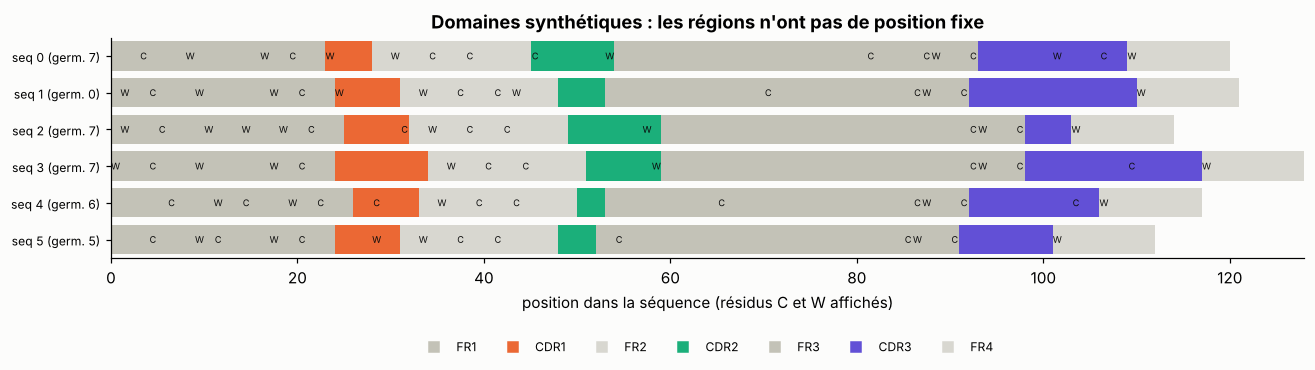

In [4]:
REGIONS = ["FR1", "CDR1", "FR2", "CDR2", "FR3", "CDR3", "FR4"]
cdr_w = np.ones(20)
for a, w in zip("YSGDTAN", [4, 3, 3, 2, 2, 1.5, 1.5]):
    cdr_w[aidx[a]] = w
cdr_p = cdr_w / cdr_w.sum()
r = np.random.default_rng(0)

def rand_seq(n, p=None):
    return "".join(r.choice(list(AA), n, p=p))

def mutate(s, rate):
    """Random substitutions, sparing the structural anchors (C and W)."""
    return "".join(AA[r.integers(20)] if (r.random() < rate and c not in "CW") else c for c in s)

def make_germlines(n=8, divergence=0.30):
    """One ancestral framework set, then n related 'germline genes' (~70% identity to the ancestor)."""
    fr1 = list(rand_seq(26)); fr1[22] = "C"                # 1st-CYS (IMGT 23)
    fr2 = list(rand_seq(17)); fr2[2] = "W"                 # conserved TRP (IMGT 41)
    fr3 = list(rand_seq(39)); fr3[-1] = "C"                # 2nd-CYS (IMGT 104)
    fr4 = "WGQG" + rand_seq(7)                             # J-region motif (IMGT 118-121)
    ancestor = ["".join(fr1), "".join(fr2), "".join(fr3), fr4]
    return [[mutate(x, divergence) for x in ancestor] for _ in range(n)]

GERMLINES = make_germlines()

def make_domain(rate=0.10):
    g = int(r.integers(len(GERMLINES)))
    fr1, fr2, fr3, fr4 = (mutate(x, rate) for x in GERMLINES[g])
    fr1 = fr1[r.integers(0, 4):]                           # random N-terminal truncation
    cdrs = [rand_seq(r.integers(5, 11), cdr_p), rand_seq(r.integers(3, 11), cdr_p), rand_seq(r.integers(5, 21), cdr_p)]
    parts = [fr1, cdrs[0], fr2, cdrs[1], fr3, cdrs[2], fr4]
    labels = np.concatenate([[k] * len(p) for k, p in enumerate(parts)])
    return "".join(parts), labels, g

domains = [make_domain() for _ in range(1600)]
cmap7 = ListedColormap(["#c3c2b7", PALETTE[1], "#d8d7d0", PALETTE[2], "#c3c2b7", PALETTE[6], "#d8d7d0"])

fig, ax = plt.subplots(figsize=(14, 2.6))
for row, (seq, lab, g) in enumerate(domains[:6]):
    ax.imshow(lab[None, :], cmap=cmap7, vmin=0, vmax=6, extent=(0, len(seq), row + 0.1, row + 0.9), aspect="auto")
    for k, c in enumerate(seq):
        if c in "CW":
            ax.text(k + 0.5, row + 0.5, c, ha="center", va="center", fontsize=6, color="#0b0b0b")
ax.set_ylim(6, 0); ax.set_xlim(0, max(len(d[0]) for d in domains[:6])); ax.set_yticks(np.arange(6) + 0.5)
ax.set_yticklabels([f"seq {i} (germ. {d[2]})" for i, d in enumerate(domains[:6])], fontsize=8); ax.grid(False)
ax.set_xlabel("position dans la séquence (résidus C et W affichés)")
for k, name in enumerate(REGIONS):
    ax.plot([], [], "s", color=cmap7(k), label=name)
ax.legend(ncol=7, loc="upper center", bbox_to_anchor=(0.5, -0.32), fontsize=8)
ax.set_title("Domaines synthétiques : les régions n'ont pas de position fixe")
plt.show()
print(domains[0][0], len(domains[0][0]))

## 5. Baseline par fenêtre glissante et décodage structuré

### Une baseline sans deep learning

Classifier chaque résidu à partir de la **fenêtre** de $\pm 7$ résidus autour de lui (one-hot, 15 × 21 caractéristiques), avec une régression logistique. C'est l'équivalent protéique des n-grammes du module 2. Le split est fait **par germinal** (module 8) : les germinaux du test ne sont jamais vus à l'entraînement, ce qui teste la généralisation à de nouvelles charpentes.

In [5]:
from sklearn.linear_model import LogisticRegression

W_win = 7
def window_features(seq):
    oh = np.zeros((len(seq) + 2 * W_win, 21)); oh[:W_win, 20] = 1; oh[-W_win:, 20] = 1    # 21st symbol = padding
    for i, a in enumerate(seq):
        oh[W_win + i, aidx[a]] = 1
    return np.stack([oh[i:i + 2 * W_win + 1].ravel() for i in range(len(seq))])

test_germs = {6, 7}                                            # split BY GERMLINE (module 8)
train_d = [d for d in domains if d[2] not in test_germs][:1000]
test_d = [d for d in domains if d[2] in test_germs][:300]
X_tr = np.vstack([window_features(s) for s, _, _ in train_d]); y_tr = np.concatenate([l for _, l, _ in train_d])
win_clf = LogisticRegression(max_iter=300, C=1.0).fit(X_tr, y_tr)
print(f"{len(train_d)} training domains ({len(y_tr):,} residues), {len(test_d)} test domains from unseen germlines")

1000 training domains (117,736 residues), 300 test domains from unseen germlines


### 📐 Le décodage structuré (Viterbi)

Le classifieur prédit chaque résidu **indépendamment**. Il peut produire des étiquettes impossibles : un résidu « CDR2 » isolé au milieu de FR1, des régions dans le désordre. Or on **connaît** la structure : la séquence d'étiquettes doit être de la forme $\text{FR1}^+\,\text{CDR1}^+\,\text{FR2}^+\dots\text{FR4}^+$. On cherche donc le **meilleur chemin valide** :
$$
\hat y = \arg\max_{y\ \text{valide}}\ \sum_{t=1}^{T}\log p(y_t\mid x)
$$
Les seules transitions autorisées sont « rester dans la même région » ou « passer à la suivante ». La **programmation dynamique** (algorithme de Viterbi) trouve l'optimum exact en $O(T\cdot K)$ : $\delta_t(k) = \log p(y_t = k\mid x) + \max\big(\delta_{t-1}(k),\ \delta_{t-1}(k-1)\big)$.

C'est l'idée d'un **CRF** (*conditional random field*) au-dessus d'un BiLSTM ou d'un Transformer (module 4), réduite à des transitions dures. Elle s'applique telle quelle aux sorties d'un PLM affiné.

In [6]:
def viterbi_ordered(logp):
    """Best label path where labels can only stay or move to the next region (0 -> 1 -> ... -> K-1)."""
    T, K = logp.shape
    dp = np.full((T, K), -np.inf); back = np.zeros((T, K), dtype=int)
    dp[0, 0] = logp[0, 0]                                      # must start in FR1
    for t in range(1, T):
        stay, advance = dp[t - 1], np.r_[-np.inf, dp[t - 1, :-1]]
        back[t] = np.where(advance > stay, np.arange(K) - 1, np.arange(K))
        dp[t] = np.maximum(stay, advance) + logp[t]
    path = [K - 1]                                             # must end in FR4
    for t in range(T - 1, 0, -1):
        path.append(back[t, path[-1]])
    return np.array(path[::-1])

def region_starts(labels):
    return [int(np.argmax(labels == k)) if (labels == k).any() else -1 for k in range(1, 7)]

stats = {"indépendant": {"res": [], "exact": [], "tol1": [], "valid": []}, "Viterbi": {"res": [], "exact": [], "tol1": [], "valid": []}}
examples = []
for seq, lab, g in test_d:
    logp = win_clf.predict_log_proba(window_features(seq))
    for name, pred in [("indépendant", logp.argmax(1)), ("Viterbi", viterbi_ordered(logp))]:
        valid = bool(np.all(np.diff(pred) >= 0) and np.all(np.diff(pred) <= 1) and pred[0] == 0 and pred[-1] == 6)
        b_true, b_pred = region_starts(lab), region_starts(pred)
        stats[name]["res"].append((pred == lab).mean())
        stats[name]["exact"].append(np.mean([a == b for a, b in zip(b_true, b_pred)]))
        stats[name]["tol1"].append(np.mean([abs(a - b) <= 1 for a, b in zip(b_true, b_pred)]))
        stats[name]["valid"].append(valid)
    if len(examples) < 3:
        examples.append((seq, lab, logp.argmax(1), viterbi_ordered(logp)))

for name, s in stats.items():
    print(f"{name:12s} residue acc {np.mean(s['res']):.3f} | exact boundaries {np.mean(s['exact']):.3f} | "
          f"boundaries ±1 {np.mean(s['tol1']):.3f} | valid label paths {np.mean(s['valid']):.0%}")

indépendant  residue acc 0.817 | exact boundaries 0.449 | boundaries ±1 0.491 | valid label paths 0%
Viterbi      residue acc 0.951 | exact boundaries 0.818 | boundaries ±1 0.846 | valid label paths 100%


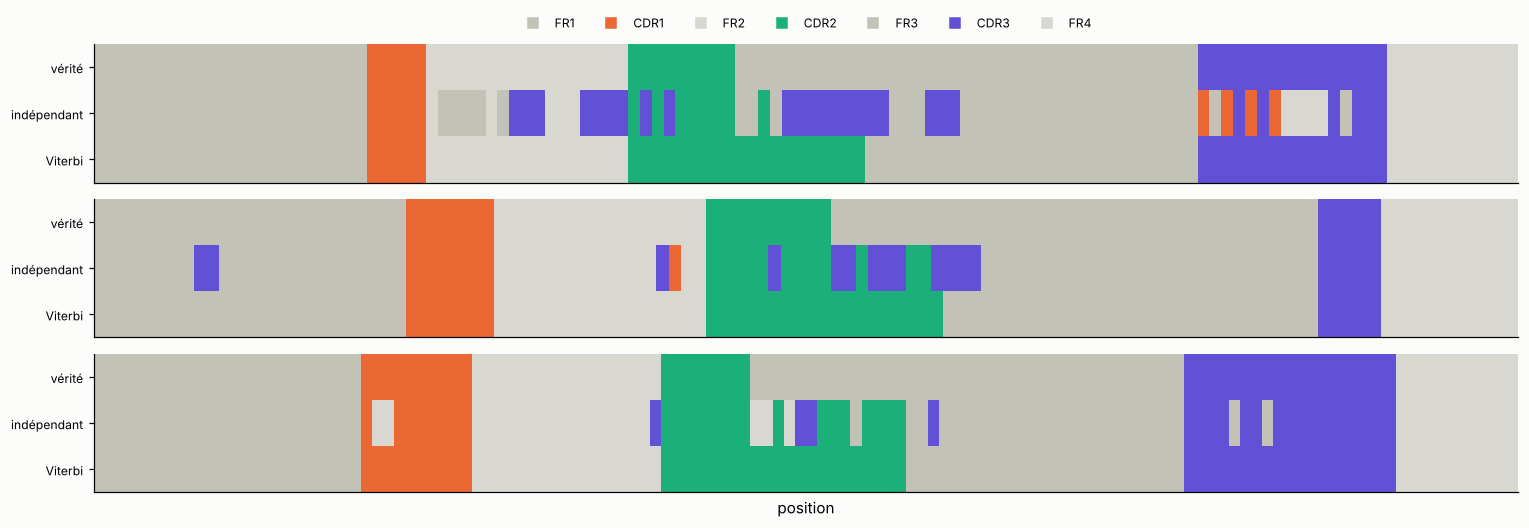

In [7]:
fig, axes = plt.subplots(len(examples), 1, figsize=(14, 1.3 * len(examples) + 1.0))
for ax, (seq, lab, raw, vit) in zip(axes, examples):
    M = np.stack([lab, raw, vit])
    ax.imshow(M, cmap=cmap7, vmin=0, vmax=6, aspect="auto")
    ax.set_yticks([0, 1, 2]); ax.set_yticklabels(["vérité", "indépendant", "Viterbi"], fontsize=8); ax.grid(False)
    ax.set_xticks([])
for k, name in enumerate(REGIONS):
    axes[0].plot([], [], "s", color=cmap7(k), label=name)
axes[0].legend(ncol=7, loc="lower center", bbox_to_anchor=(0.5, 1.02), fontsize=8)
axes[-1].set_xlabel("position")
plt.tight_layout(); plt.show()

**Lecture critique** :
- la prédiction indépendante a une précision par résidu honorable, mais produit des **chemins invalides** presque systématiquement ; ses frontières exactes sont rarement justes ;
- le décodage contraint **ne coûte rien** (aucun réentraînement) et améliore fortement les frontières : c'est un gain « gratuit » de connaissance du domaine ;
- les erreurs restantes se concentrent aux **frontières** des CDR (dans les exemples ci-dessus, la fin de la CDR2 déborde sur FR3) : là où une charpente mutée et une CDR se ressemblent localement. Une fenêtre de ±7 résidus ne voit pas assez loin pour exploiter les ancres (« combien de résidus depuis le Trp conservé ? »). C'est précisément ce qu'un Transformer, qui voit toute la séquence, peut apprendre.

## 6. ESM-2 avec Hugging Face : embeddings et pseudo-perplexité

ESM-2 (Lin et al., 2023) est un encodeur de type BERT (Pre-LN, **RoPE**, module 6) pré-entraîné en MLM sur UniRef. Tailles disponibles sur le Hub :

| Identifiant | Couches | $d$ | Paramètres |
|---|---|---|---|
| `facebook/esm2_t6_8M_UR50D` | 6 | 320 | 8 M |
| `facebook/esm2_t12_35M_UR50D` | 12 | 480 | 35 M |
| `facebook/esm2_t30_150M_UR50D` | 30 | 640 | 150 M |
| `facebook/esm2_t33_650M_UR50D` | 33 | 1280 | 650 M |

Commence toujours par le plus petit pour mettre au point le code, puis monte en taille.

In [ ]:
import torch
import torch.nn.functional as F
from transformers import AutoTokenizer, AutoModel, AutoModelForMaskedLM

device = "cuda" if torch.cuda.is_available() else "cpu"
esm_name = "facebook/esm2_t12_35M_UR50D"
esm_tok = AutoTokenizer.from_pretrained(esm_name)
print(esm_tok.all_tokens if hasattr(esm_tok, "all_tokens") else esm_tok.get_vocab())

seq0 = domains[0][0]
enc = esm_tok(seq0, return_tensors="pt")
print(len(seq0), "residues ->", enc["input_ids"].shape[1], "tokens:", esm_tok.convert_ids_to_tokens(enc["input_ids"][0][:8]), "...")

esm = AutoModel.from_pretrained(esm_name).to(device).eval()

@torch.no_grad()
def residue_embeddings(seq):
    enc = esm_tok(seq, return_tensors="pt").to(device)
    h = esm(**enc).last_hidden_state[0]           # (L + 2, d): <cls> + residues + <eos>
    return h[1:-1].cpu()                          # (L, d): one vector per residue

@torch.no_grad()
def sequence_embedding(seq):
    return residue_embeddings(seq).mean(0)       # mean over residues (special tokens excluded)

E = torch.stack([sequence_embedding(s) for s, _, _ in domains[:400]]).numpy()
germ = np.array([g for _, _, g in domains[:400]])
from sklearn.decomposition import PCA
Z = PCA(2).fit_transform(E)
plt.scatter(Z[:, 0], Z[:, 1], c=germ, cmap="tab10", s=8)
plt.title("Embeddings ESM-2 (moyenne par séquence), colorés par germinal"); plt.show()

> ⚠️ Nos séquences synthétiques ont des charpentes **aléatoires**, très différentes de vraies protéines : ESM-2 les trouvera « étranges » (perplexité élevée). Sur de vraies séquences d'anticorps, ces démonstrations prennent tout leur sens.

**La pseudo-perplexité** (Salazar et al., 2020) : un MLM ne donne pas directement $p(x)$ ; on masque chaque position tour à tour et on moyenne :
$$
\text{PPPL}(x) = \exp\!\left(-\frac{1}{L}\sum_{i=1}^{L}\log p_\theta(x_i\mid x_{\setminus i})\right)
$$
Coûteux ($L$ passes avant), mais c'est l'indicateur standard pour suivre un DAPT (module 8) ou repérer des séquences atypiques.

In [ ]:
mlm = AutoModelForMaskedLM.from_pretrained(esm_name).to(device).eval()

@torch.no_grad()
def pseudo_perplexity(seq, batch_size=32):
    ids = esm_tok(seq, return_tensors="pt")["input_ids"][0]
    L = len(seq)
    masked = ids.repeat(L, 1)                                   # one copy per residue to mask
    pos = torch.arange(1, L + 1)                                # residue i is at token i (token 0 = <cls>)
    masked[torch.arange(L), pos] = esm_tok.mask_token_id
    nll = 0.0
    for k in range(0, L, batch_size):
        logits = mlm(input_ids=masked[k:k + batch_size].to(device)).logits      # (b, L+2, V)
        lp = logits.log_softmax(-1)[torch.arange(len(logits)), pos[k:k + batch_size]]   # (b, V)
        nll -= lp[torch.arange(len(lp)), ids[pos[k:k + batch_size]]].sum().item()
    return float(np.exp(nll / L))

print("synthetic domain PPPL:", round(pseudo_perplexity(domains[0][0]), 2))
print("ubiquitin PPPL       :", round(pseudo_perplexity("MQIFVKTLTGKTITLEVEPSDTIENVKAKIQDKEGIPPDQQRLIFAGKQLEDGRTLSDYNIQKESTLHLVLRLRGG"), 2))

## 7. Affiner ESM-2 pour l'étiquetage de régions

Exactement le module 7 (section 7), en plus simple : un token par résidu. On garde le split **par germinal**, on évalue au niveau des **frontières**, et on applique le **Viterbi** de la section 5 aux log-probabilités du modèle.

In [ ]:
from datasets import Dataset
from transformers import AutoModelForTokenClassification, DataCollatorForTokenClassification, TrainingArguments, Trainer

def to_hf(dset):
    return Dataset.from_dict({"seq": [s for s, _, _ in dset], "labels_res": [l.tolist() for _, l, _ in dset]})

def tokenize_regions(batch):
    enc = esm_tok(batch["seq"], truncation=True, max_length=1024)
    enc["labels"] = [[-100] + lab + [-100] for lab in batch["labels_res"]]     # <cls>, residues, <eos>
    return enc

train_hf = to_hf([d for d in domains if d[2] not in test_germs]).map(tokenize_regions, batched=True, remove_columns=["seq", "labels_res"])
test_hf = to_hf(test_d).map(tokenize_regions, batched=True, remove_columns=["seq", "labels_res"])

region_model = AutoModelForTokenClassification.from_pretrained(
    esm_name, num_labels=7, id2label=dict(enumerate(REGIONS)), label2id={n: i for i, n in enumerate(REGIONS)})

def region_metrics(eval_pred):
    logits, labels = eval_pred
    res_acc, exact, tol1 = [], [], []
    for lg, lb in zip(logits, labels):
        keep = lb != -100
        lp = torch.tensor(lg[keep]).log_softmax(-1).numpy()
        pred, true = viterbi_ordered(lp), lb[keep]
        res_acc.append((pred == true).mean())
        bt, bp = region_starts(true), region_starts(pred)
        exact.append(np.mean([a == b for a, b in zip(bt, bp)])); tol1.append(np.mean([abs(a - b) <= 1 for a, b in zip(bt, bp)]))
    return {"residue_acc": np.mean(res_acc), "boundary_exact": np.mean(exact), "boundary_tol1": np.mean(tol1)}

args = TrainingArguments(output_dir="esm2-regions", num_train_epochs=5, learning_rate=5e-5, warmup_ratio=0.1,
                         weight_decay=0.01, per_device_train_batch_size=16, per_device_eval_batch_size=32,
                         eval_strategy="epoch", save_strategy="no", report_to="none", seed=0,
                         fp16=torch.cuda.is_available())
trainer = Trainer(model=region_model, args=args, train_dataset=train_hf, eval_dataset=test_hf,
                  data_collator=DataCollatorForTokenClassification(esm_tok), compute_metrics=region_metrics)
trainer.train()
print(trainer.evaluate())

### La version LoRA (module 8)

In [ ]:
from peft import LoraConfig, get_peft_model, TaskType

base_model = AutoModelForTokenClassification.from_pretrained(esm_name, num_labels=7)
lora_model = get_peft_model(base_model, LoraConfig(task_type=TaskType.TOKEN_CLS, r=8, lora_alpha=16,
                                                   lora_dropout=0.1, target_modules=["query", "key", "value"]))
lora_model.print_trainable_parameters()
lora_args = TrainingArguments(output_dir="esm2-regions-lora", num_train_epochs=5, learning_rate=3e-4,   # higher lr for LoRA
                              warmup_ratio=0.1, per_device_train_batch_size=16, eval_strategy="epoch",
                              save_strategy="no", report_to="none", seed=0)
Trainer(model=lora_model, args=lora_args, train_dataset=train_hf, eval_dataset=test_hf,
        data_collator=DataCollatorForTokenClassification(esm_tok), compute_metrics=region_metrics).train()

> 💡 **Extension multi-tâche** (module 8, section 4) : ajoute une tête de séquence (type de domaine, germinal, espèce…) sur la moyenne des embeddings, et combine les pertes par pondération d'incertitude. Les étiquettes manquantes (une séquence sans germinal assigné) reçoivent `-100`.

## 8. Prédiction zéro-shot de l'effet des mutations

Un PLM pré-entraîné donne, sans aucun affinage, un score de « plausibilité évolutive » d'une mutation. Le score des **marginales masquées** (Meier et al., 2021) pour une substitution $\text{wt}\to\text{mut}$ à la position $i$ :
$$
s(i, \text{wt}\to\text{mut}) = \log p_\theta(x_i = \text{mut}\mid x_{\setminus i}) - \log p_\theta(x_i = \text{wt}\mid x_{\setminus i})
$$
$s < 0$ : la mutation est moins plausible que le résidu sauvage, souvent déstabilisante ou délétère. Pour des mutations multiples, on somme les scores (hypothèse d'additivité, qui ignore l'épistasie). Ces scores corrèlent de façon significative avec les mesures expérimentales de *deep mutational scanning* (ProteinGym), sans données étiquetées.

In [ ]:
@torch.no_grad()
def mutation_scan(seq):
    """Masked-marginal scores for all 19 substitutions at every position: (L, 20) matrix."""
    ids = esm_tok(seq, return_tensors="pt")["input_ids"][0]
    aa_ids = torch.tensor([esm_tok.convert_tokens_to_ids(a) for a in AA])
    L = len(seq)
    scores = np.zeros((L, 20))
    for k in range(0, L, 32):
        pos = torch.arange(k, min(k + 32, L)) + 1
        batch = ids.repeat(len(pos), 1)
        batch[torch.arange(len(pos)), pos] = esm_tok.mask_token_id
        lp = mlm(input_ids=batch.to(device)).logits.log_softmax(-1)[torch.arange(len(pos)), pos][:, aa_ids].cpu()
        wt = torch.tensor([aidx[seq[p - 1]] for p in pos])
        scores[k:k + len(pos)] = (lp - lp[torch.arange(len(pos)), wt][:, None]).numpy()
    return scores

ubiquitin = "MQIFVKTLTGKTITLEVEPSDTIENVKAKIQDKEGIPPDQQRLIFAGKQLEDGRTLSDYNIQKESTLHLVLRLRGG"
S = mutation_scan(ubiquitin)
plt.figure(figsize=(14, 3.5))
plt.imshow(S.T, cmap="RdBu", vmin=-8, vmax=8, aspect="auto")
plt.yticks(range(20), list(AA), fontsize=7); plt.xlabel("position"); plt.colorbar(label="log p(mut) − log p(wt)")
plt.title("Paysage mutationnel zéro-shot de l'ubiquitine (ESM-2)"); plt.grid(False)
plt.show()

Les colonnes très bleues (toutes les mutations défavorables) correspondent aux positions **contraintes** : cœur hydrophobe, résidus fonctionnels, motifs comme la queue C-terminale « LRLRGG » de l'ubiquitine.

> ⚠️ **Pour un domaine d'anticorps**, attention : un PLM généraliste « préfère » souvent les résidus **germinaux** et pénalise les mutations somatiques, même bénéfiques à l'affinité. Ce **biais germinal** est documenté pour les modèles d'anticorps eux-mêmes (AbLang-2, Olsen et al., 2024, a été conçu pour le réduire). Un score zéro-shot mesure une plausibilité évolutive, pas une fonction.

## 9. Modèles spécialisés, DAPT et pièges propres au domaine

### Modèles généralistes vs spécialisés

- **Généralistes** : ESM-2, ProtT5, ESM C… pré-entraînés sur UniRef, où les anticorps sont relativement peu représentés après réduction de redondance.
- **Spécialisés anticorps** : AntiBERTy (Ruffolo et al., 2021), AbLang / AbLang-2 (Olsen et al., 2022 ; 2024), AntiBERTa (Leem et al., 2022), Sapiens (Prihoda et al., 2022), IgBert / IgT5 (Kenlay et al., 2024), pré-entraînés sur l'Observed Antibody Space (OAS, des centaines de millions à plus d'un milliard de séquences).
- **Entre les deux : le DAPT** (module 8) d'un modèle généraliste sur un corpus du domaine (OAS, IMGT), puis éventuellement un **TAPT** sur les séquences de la tâche. C'est une **question expérimentale**, à trancher par ablation contre ces deux familles de modèles.

### Les pièges propres au domaine

| Piège | Pourquoi | Parade |
|---|---|---|
| Fuite par homologie | les séquences proches se ressemblent par descendance | splits par cluster d'identité, par germinal ou par clonotype ; scores en fonction de l'identité au train (module 8) |
| Redondance des données | des clones très nombreux sur-représentent certains germinaux | déduplication, pondération ou échantillonnage par cluster |
| Biais germinal | les mutations somatiques sont « improbables » pour le modèle | modèles conçus pour le réduire, affinage supervisé, évaluation séparée des positions mutées |
| Domaines multiples, séquences longues | une chaîne complète dépasse un domaine ; contexte limité (1 024 tokens pour ESM-2) | découper par domaine, ou utiliser des fenêtres glissantes avec recouvrement |
| Étiquettes de référence elles-mêmes calculées | les annotations « vérité » viennent souvent d'un outil (alignement aux germinaux) | évaluer aussi sur un sous-ensemble expertisé ; analyser les désaccords modèle / outil au cas par cas |
| Espèces et loci rares | peu de données pour certains loci (TR, espèces non modèles) | rapporter les scores **par espèce et par locus**, pas seulement en moyenne |

## 10. Récapitulatif

| Notion | À retenir |
|---|---|
| Analogie | séquences = phrases, résidus = tokens, évolution = locuteur ; MLM = BERT sur UniRef |
| Tokenisation | un token par résidu (V ≈ 33) ; alignement étiquettes trivial ; `<cls>`/`<eos>` → `-100` |
| Co-évolution | colonnes couplées ↔ contacts ; MI + APC ; les PLM l'internalisent |
| Étiquetage de régions | token classification + **décodage contraint** (Viterbi / CRF) ; évaluer les frontières (exactes et ±1) |
| ESM-2 | encodeur Pre-LN + RoPE, 8 M à 15 G paramètres ; embeddings par résidu / par séquence |
| Pseudo-perplexité | masquer chaque position ; suivi du DAPT |
| Zéro-shot | $\log p(\text{mut}) - \log p(\text{wt})$ aux positions masquées |
| Méthodologie | splits par homologie / germinal, biais germinal, scores par espèce et locus |

### 🏋️ Exercices

1. **Taille de fenêtre.** Fais varier `W_win` de 2 à 15 dans la baseline. La précision des frontières de CDR3 suit-elle la même tendance que celle de CDR1 ? Pourquoi ?
2. **Viterbi avec contraintes de longueur.** Étends `viterbi_ordered` pour imposer une longueur minimale et maximale à chaque région (par exemple CDR1 de 5 à 12). Indice : ajoute la durée passée dans la région courante à l'état (*semi-Markov*), ou déplie chaque région en une chaîne d'états.
3. **Co-évolution vs phylogénie.** Dans la démonstration MI, génère le MSA à partir d'un **arbre** (des sous-familles qui partagent des mutations) plutôt que de séquences indépendantes. Que devient la précision de la MI brute ? Et avec APC ?
4. **ESM-2 vs baseline.** Compare, sur le même split par germinal, la baseline par fenêtre + Viterbi, ESM-2 35M affiné, et ESM-2 35M + LoRA. Rapporte frontières exactes et ±1, avec 3 graines et des IC bootstrap (module 8).
5. **Ton projet.** Rédige le protocole d'ablation pour comparer : (a) ESM-2 affiné directement, (b) ESM-2 + DAPT sur des séquences d'anticorps, (c) un modèle spécialisé anticorps, chacun en mono-tâche et en multi-tâche. Quels splits ? Quelles métriques ? Quel test statistique ?

<details><summary>Indications</summary>

1. La CDR3 est longue et variable : ses frontières dépendent d'un contexte large (2e Cys d'un côté, motif W-G-Q-G de l'autre). Une fenêtre trop petite ne voit pas ces deux ancres à la fois.
2. Version simple : remplace chaque région $k$ par une chaîne de $\text{max}_k$ états $k_1\to k_2\to\dots$ où l'on ne peut sortir vers la région suivante qu'à partir de $k_{\text{min}_k}$.
3. La phylogénie crée des corrélations entre **toutes** les positions qui ont muté sur une même branche : la MI brute se remplit de faux positifs ; APC en retire une partie. Les méthodes à modèle global (DCA, *pseudo-likelihood*) font mieux encore.
</details>

---

### 🎓 Fin du parcours

Tu as maintenant suivi le fil complet : du neurone et de la rétropropagation (module 0) jusqu'aux modèles de langage de protéines, en passant par la tokenisation, les embeddings, les RNN, l'attention, le Transformer, le pré-entraînement, l'adaptation et la méthodologie d'évaluation. Chaque brique d'un modèle comme ESM-2 a été codée au moins une fois de zéro dans ce cours.

**Pour aller plus loin** :
- Vaswani et al. (2017), *Attention Is All You Need* ; Devlin et al. (2019), *BERT* ; Radford et al. (2019), *GPT-2*.
- Gururangan et al. (2020), *Don't Stop Pretraining* ; Hu et al. (2021), *LoRA* ; Kendall, Gal & Cipolla (2018), *Multi-Task Learning Using Uncertainty to Weigh Losses*.
- Rives et al. (2021) et Lin et al. (2023) pour ESM / ESM-2 ; Rao et al. (2021), *Transformer protein language models are unsupervised structure learners* ; Meier et al. (2021), *Language models enable zero-shot prediction of the effects of mutations*.
- Ruffolo et al. (2021), Olsen et al. (2022, 2024), Leem et al. (2022) pour les modèles de langage d'anticorps.
- Le cours *nanoGPT* / *Zero to Hero* d'A. Karpathy, et le livre *Natural Language Processing with Transformers* (Tunstall, von Werra, Wolf).